In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

CIBLE = "TousAge_allergie_urgences"
EXOS = ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10',
        'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
        'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1',
        'pression_mer', 'tendance_pression_3h', 'vent_vitesse', 'temperature_kelvin',
        'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h',
        'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers',
        'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure',
        'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages',
        'tp_tempete_poussiere_chasse_neige',
        'TousAge_asthme_urgences', 'TousAge_asthme_hospitalisation',
        '0an_bronchiolite_urgences', 'TousAge_allergie_hospitalisation',
        'prev_calc_Maladie_Respi_Chronique_0-14_9',
        'prev_calc_Maladie_Respi_Chronique_15-64_9',
        'prev_calc_Maladie_Respi_Chronique_65+_9',
        'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes',
        'pct_ouvriers', 'pct_retraites', 'pct_agriculteurs',
        'densite_generalistes', 'densite_pediatres', 'densite_pneumologues',
        'densite_allergologues', 'densite_kines',
        'sos_present']

H = 1  # nombre de semaines futures moyennées dans la cible

# une ligne par département et par semaine t, cible = moyenne de y(t+1) à y(t+H)
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")
    y, sem = d[CIBLE], d.index.isocalendar().week.astype(float)
    moy_glis = y.rolling(H, min_periods=H).mean()  # moyenne de y(t-H+1) à y(t), NaN s'il manque une semaine
    bloc = pd.DataFrame({
        "code_dept": dept,
        "date_debut": d.index + pd.Timedelta(weeks=1),  # première semaine de la fenêtre cible
        "date_fin": d.index + pd.Timedelta(weeks=H),  # dernière semaine de la fenêtre cible
        "cible": moy_glis.shift(-H),
        "y_passe": moy_glis,
        "y_lag0": y, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "sem_sin": np.sin(2 * np.pi * sem / 52.18),
        "sem_cos": np.cos(2 * np.pi * sem / 52.18),
    })
    for c in EXOS:
        bloc[c] = d[c]
    morceaux.append(bloc)
panel = pd.concat(morceaux).dropna(subset=["cible", "y_passe", "y_lag0", "y_lag1", "y_lag2"])

an = panel["date_fin"].dt.year
panel["split"] = "test"
panel.loc[an <= 2022, "split"] = "train"
panel.loc[an == 2023, "split"] = "val"

# baseline 1, persistance 
panel["base_persist"] = panel["y_passe"]
# baseline 2, profil saisonnier 
panel["sem_debut"] = panel["date_debut"].dt.isocalendar().week.astype(int)
profil = panel[panel["split"] == "train"].groupby(["code_dept", "sem_debut"])["cible"].mean()
profil = profil.rename("base_saison")
panel = panel.join(profil, on=["code_dept", "sem_debut"])

def scores(y_vrai, y_pred):
    return {"R2": r2_score(y_vrai, y_pred),
            "MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5}

val = panel[panel["split"] == "val"].dropna(subset=["base_saison"])
print(panel["split"].value_counts())
print("Persistance :", scores(val["cible"], val["base_persist"]))
print("Profil saisonnier :", scores(val["cible"], val["base_saison"]))

split
train    9696
val      4992
test     4992
Name: count, dtype: int64
Persistance : {'R2': 0.10406010438441571, 'MAE': 219.0278099115345, 'RMSE': 306.1079964711084}
Profil saisonnier : {'R2': 0.24309945964229396, 'MAE': 204.9145384364762, 'RMSE': 281.3550045842997}


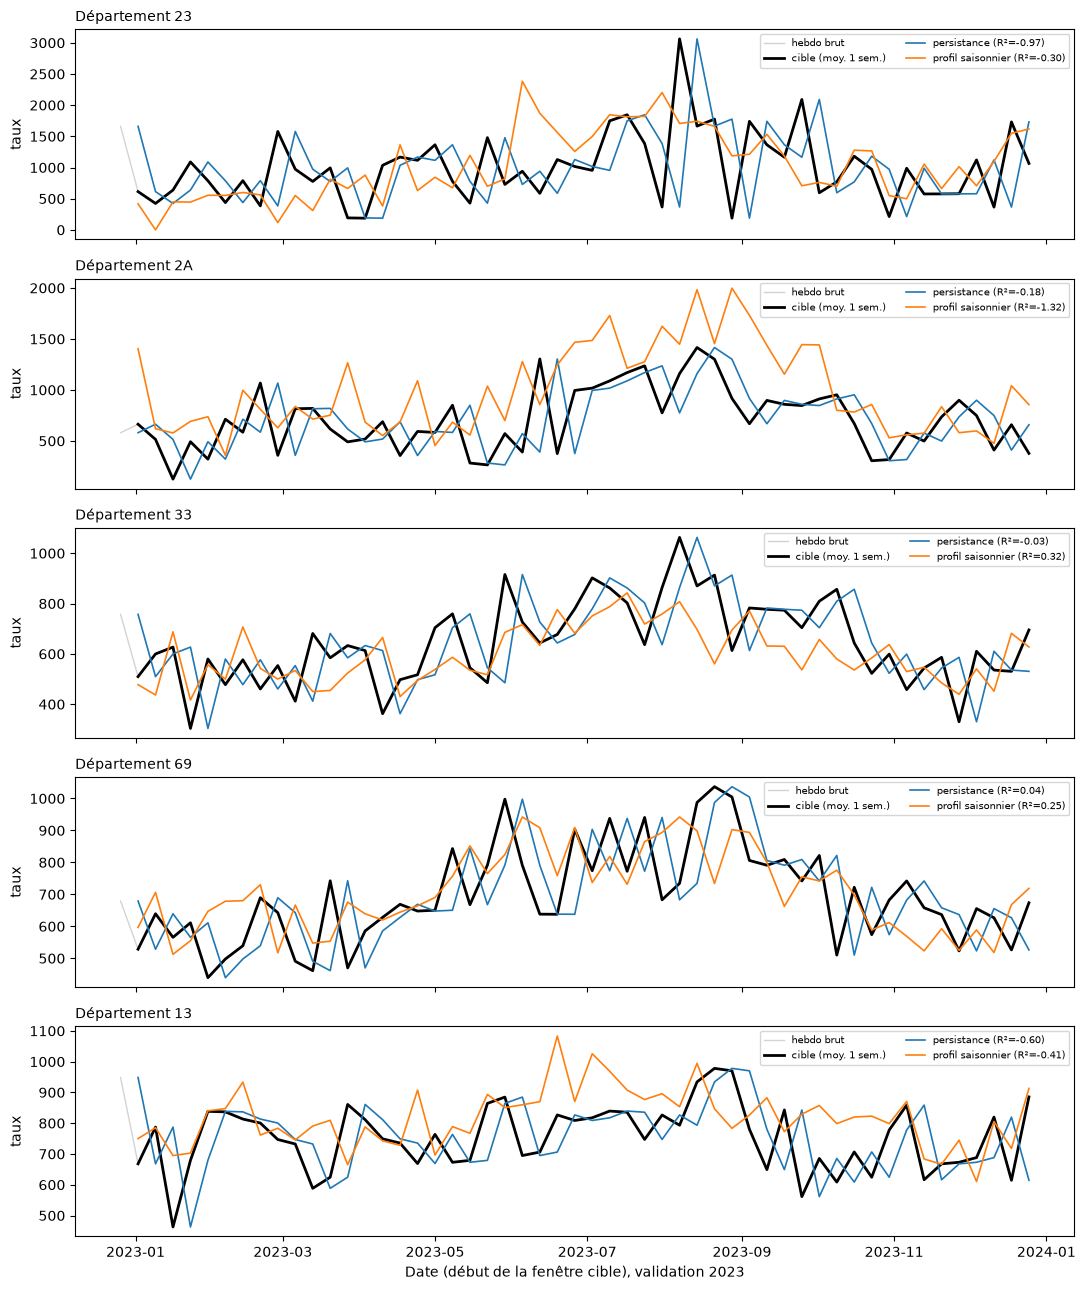

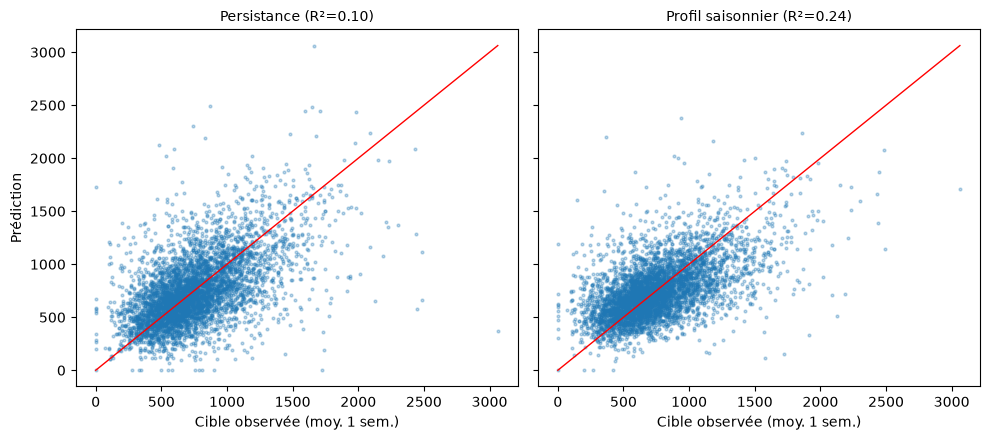

In [26]:
DEPTS = ["23", "2A", "33", "69", "13"] 

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = val[val["code_dept"] == dept].sort_values("date_debut")
    sc_p = scores(v["cible"], v["base_persist"])["R2"]
    sc_s = scores(v["cible"], v["base_saison"])["R2"]

    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["date_debut"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    ax.plot(v["date_debut"], v["base_persist"], color="tab:blue", lw=1.2,
            label=f"persistance (R²={sc_p:.2f})")
    ax.plot(v["date_debut"], v["base_saison"], color="tab:orange", lw=1.2,
            label=f"profil saisonnier (R²={sc_s:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (début de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, col, nom in zip(axes, ["base_persist", "base_saison"], ["Persistance", "Profil saisonnier"]):
    ax.scatter(val["cible"], val[col], s=4, alpha=0.3)
    lim = [0, val[["cible", col]].max().max()]
    ax.plot(lim, lim, color="red", lw=1)  # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(val['cible'], val[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

FEATURES = ["y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos"] + EXOS

modele = Pipeline([("scaler", StandardScaler()), ("reg", LinearRegression())])

train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible"])

modele.fit(train[FEATURES], train["cible"])
print("LR val :", scores(val_m["cible"], modele.predict(val_m[FEATURES])))

LR val : {'R2': 0.4472944521025196, 'MAE': 174.9416885034418, 'RMSE': 238.9508195539749}


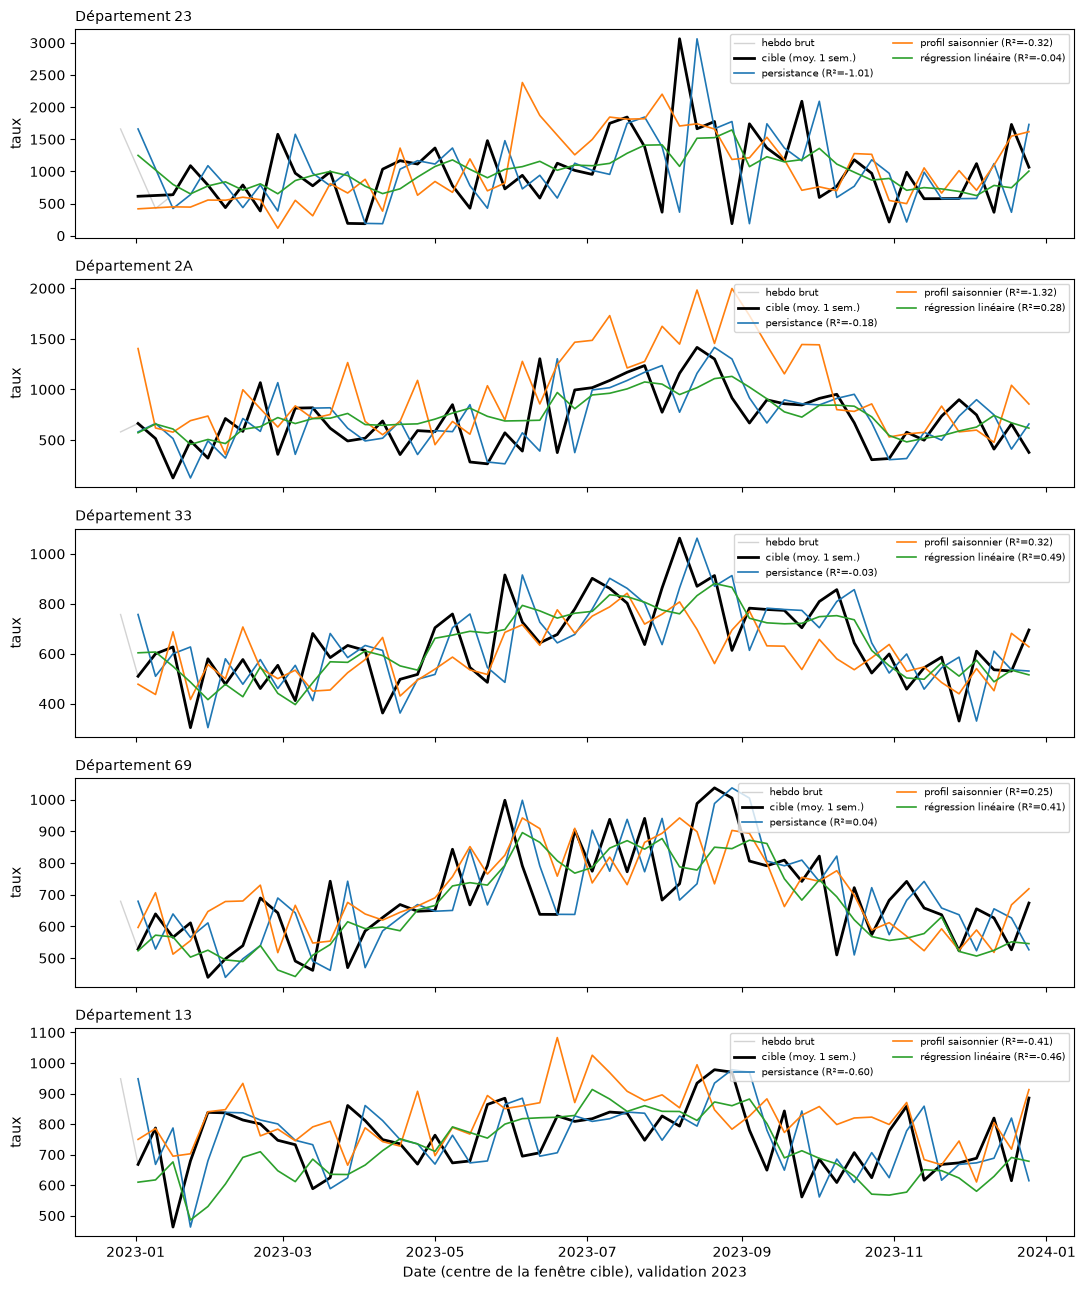

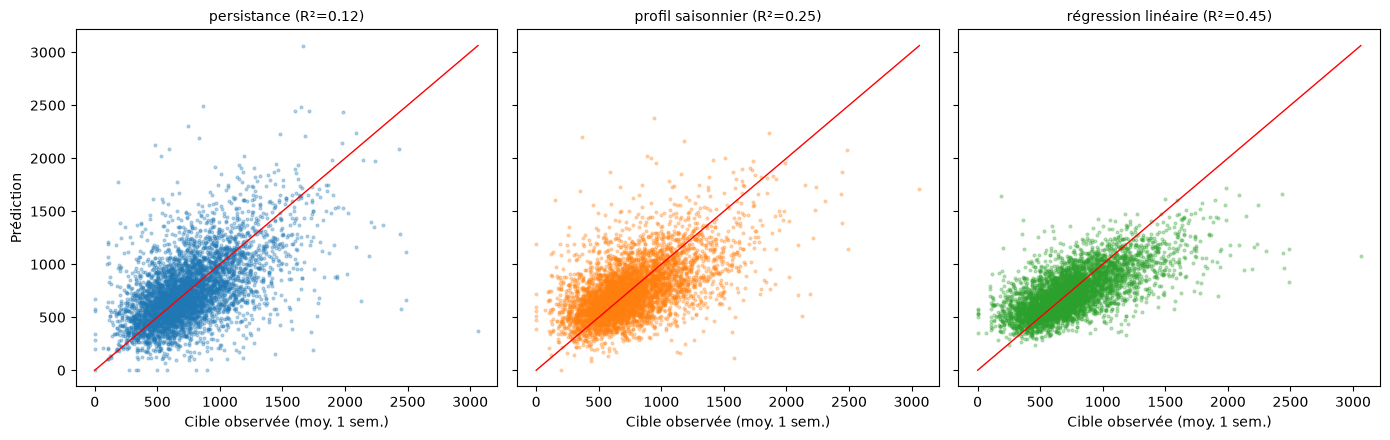

In [28]:
# prédictions du modèle sur validation
v_all = val_m.dropna(subset=["base_saison"]).copy()
v_all["pred_LR"] = modele.predict(v_all[FEATURES])
v_all["centre"] = v_all["date_debut"] + pd.Timedelta(weeks=(H - 1) / 2)

SERIES = [("base_persist", "persistance", "tab:blue"),
          ("base_saison", "profil saisonnier", "tab:orange"),
          ("pred_LR", "régression linéaire", "tab:green")]

# séries temporelles par département
fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = v_all[v_all["code_dept"] == dept].sort_values("date_debut")
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["centre"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    for col, nom, coul in SERIES:
        r2 = scores(v["cible"], v[col])["R2"]
        ax.plot(v["centre"], v[col], color=coul, lw=1.2, label=f"{nom} (R²={r2:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (centre de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(SERIES), figsize=(14, 4.5), sharex=True, sharey=True)
colonnes = ["cible", "base_persist", "base_saison", "pred_LR"]
lim = [0, v_all[colonnes].max().max()]
for ax, (col, nom, coul) in zip(axes, SERIES):
    ax.scatter(v_all["cible"], v_all[col], s=4, alpha=0.3, color=coul)
    ax.plot(lim, lim, color="red", lw=1) 
    ax.set_title(f"{nom} (R²={scores(v_all['cible'], v_all[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [29]:
import glob
import json
import os
import re
import unicodedata

DOSSIER = "../data/pollens/"
TAXONS = ["GRAMINEE"]
TAXON = "GRAMINEES"
JSON_ST = DOSSIER + "stations_departements.json"
MIN_JOURS = 4  

# harmonisation nom de station
def norm(nom):
    nom = unicodedata.normalize("NFKD", str(nom)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Z]", "", nom.upper())

print("Taxons retenus :", TAXONS, "; minimum", MIN_JOURS, "jours de mesure par semaine")
print("Exemple harmonisation :", norm("Aix-en-Provence"))

Taxons retenus : ['GRAMINEE'] ; minimum 4 jours de mesure par semaine
Exemple harmonisation : AIXENPROVENCE


In [30]:
liste = glob.glob(DOSSIER + "liste*station*.xlsx")
assert len(liste) == 1, f"Liste des stations introuvable ou en plusieurs exemplaires : {liste}"

if not os.path.exists(JSON_ST):
    import geopandas as gpd
    stations = pd.read_excel(liste[0])
    url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
    depts = gpd.read_file(url)[["code", "geometry"]].to_crs(2154)  # projection en mètres
    pts = gpd.GeoDataFrame(stations[["Stations"]], crs=4326,
                           geometry=gpd.points_from_xy(stations["Longitude"], stations["Latitude"]))
    pts = pts.to_crs(2154)
    j = gpd.sjoin(pts, depts, how="left", predicate="within")
    j = j[~j.index.duplicated()]

    manq = j["code"].isna()
    if manq.any():
        proche = gpd.sjoin_nearest(pts[manq], depts, how="left", max_distance=10000)
        j.loc[manq, "code"] = proche[~proche.index.duplicated()]["code"]
    corresp = {}
    for s, c in zip(j["Stations"], j["code"]):
        if pd.notna(c):
            corresp[norm(s)] = c
    with open(JSON_ST, "w", encoding="utf-8") as f:
        json.dump(corresp, f, ensure_ascii=False, indent=1)
    print(JSON_ST, "créé :", len(corresp), "stations")
    print("Stations hors France :", sorted(j.loc[j["code"].isna(), "Stations"]))

with open(JSON_ST, encoding="utf-8") as f:
    STATION_DEPT = json.load(f)

print(len(STATION_DEPT), "stations rattachées à", len(set(STATION_DEPT.values())), "départements")

122 stations rattachées à 78 départements


In [31]:
def lire(chemin):
    t = pd.read_excel(chemin)
    entete = t.columns[0]  
    presents = [c for c in TAXONS if c in t.columns]
    if not presents:
        return None
    t = pd.DataFrame({"date": pd.to_datetime(t[entete], errors="coerce"),
                      "pollen": t[presents].sum(axis=1, min_count=1)})  # NaN si aucun taxon mesuré
    t = t.dropna(subset=["date"])
    m = re.match(r"Particle_Extract_(.+?)_\d{4}-\d{2}-\d{2}", os.path.basename(chemin))
    if m:
        t["nom_fichier"] = m.group(1)
    else:
        t["nom_fichier"] = entete
    t["entete"] = entete
    t["n_taxons"] = len(presents)
    return t

morceaux = []
sans_taxon = []
n_fichiers = {}
for dossier in sorted(glob.glob(DOSSIER + "20[0-9][0-9]")):
    annee = int(os.path.basename(dossier))
    fichiers = sorted(glob.glob(os.path.join(dossier, "Particle_Extract_*.xls")))
    n_fichiers[annee] = len(fichiers)
    for f in fichiers:
        t = lire(f)
        if t is None:
            sans_taxon.append(f"{annee}/{os.path.basename(f)}")
        else:
            t["annee"] = annee
            t["fichier"] = os.path.basename(f)
            morceaux.append(t)
pol = pd.concat(morceaux, ignore_index=True)

print(len(pol), "mesures lues dans", sum(n_fichiers.values()), "fichiers")
print("Période :", pol["date"].min().date(), "à", pol["date"].max().date())

92647 mesures lues dans 254 fichiers
Période : 2021-01-01 à 2023-12-31


In [32]:
def sous_suite(court, long):
    i = 0
    for lettre in long:
        if i < len(court) and lettre == court[i]:
            i += 1
    return i == len(court)

# stations correspondant à un nom : identique, sinon préfixe, sinon abréviation
def candidats(nom):
    k = norm(nom)
    c = [s for s in STATION_DEPT if s == k]
    if not c:
        c = [s for s in STATION_DEPT if s.startswith(k)]
    if not c and len(k) >= 6:
        c = [s for s in STATION_DEPT if s[0] == k[0] and sous_suite(k, s)]
    return c

noms = pol[["nom_fichier", "entete"]].drop_duplicates()
cand = []
for f, e in zip(noms["nom_fichier"], noms["entete"]):
    c = candidats(f)
    if len(c) != 1:
        c = candidats(e)
    cand.append(c)

uniques = {c[0] for c in cand if len(c) == 1}
trouvees = []
for c in cand:
    if len(c) > 1:
        c = [s for s in c if s not in uniques]
    trouvees.append(c[0] if len(c) == 1 else None)
noms["station"] = trouvees

pol = pol.merge(noms[["nom_fichier", "entete", "station"]], on=["nom_fichier", "entete"], how="left")
pol["code_dept"] = pol["station"].map(STATION_DEPT)

print("Rattachements à vérifier :")
a_verifier = noms[noms["station"].notna() & (noms["station"] != noms["nom_fichier"].map(norm))]
print(a_verifier[["nom_fichier", "entete", "station"]].sort_values("entete").to_string(index=False))

Rattachements à vérifier :
nom_fichier   entete             station
   AIXENPRO AIXENPRO       AIXENPROVENCE
   ANGOULEM ANGOULEM           ANGOULEME
   ANNEMASS ANNEMASS           ANNEMASSE
   BLETTERA BLETTERA          BLETTERANS
   BORDPESS BORDPESS      BORDEAUXPESSAC
   BOURGENB BOURGENB       BOURGENBRESSE
   BOURGOIN BOURGOIN     BOURGOINJALLIEU
      BREST    BREST            BRESTREG
   BRUSSLAN BRUSSLAN     BRUSSIEULANZONI
   CHALON-S CHALON-S      CHALONSURSAONE
   CHARLEVI CHARLEVI         CHARLEVILLE
   CLERMONT CLERMONT     CLERMONTFERRAND
   DRAGUIGN DRAGUIGN          DRAGUIGNAN
   LAROCHE- LAROCHE-       LAROCHESURYON
    LAROCHL  LAROCHL          LAROCHELLE
   LEPUYENV LEPUYENV        LEPUYENVELAY
   MARSEILL MARSEILL           MARSEILLE
   MONTLUCO MONTLUCO           MONTLUCON
   MONTPELL MONTPELL         MONTPELLIER
   MTMARSAN MTMARSAN        MONTDEMARSAN
   ROUSSILL ROUSSILL          ROUSSILLON
   SAINT-ET SAINT-ET        SAINTETIENNE
   SAINTDIE SAINTDIE   SAINTDI

In [33]:
non_ratt = sorted(noms.loc[noms["station"].isna(), "entete"])
hors_annee = sorted(pol.loc[pol["date"].dt.year != pol["annee"], "fichier"].unique())
n_dup = (pol["station"].notna() & pol.duplicated(["station", "date"])).sum()
nt = pol.groupby("fichier")["n_taxons"].first()

print("Fichiers lus par année :", n_fichiers)
print("Fichiers sans", TAXON, ":", sans_taxon)
print("Fichiers avec des dates hors de l'année :", hors_annee)
print("Noms non rattachés (ignorés) :", non_ratt)
print("Doublons station / date (supprimés à l'agrégation) :", n_dup)
print("Fichiers avec moins de taxons que le maximum :", nt[nt < nt.max()].to_dict())

Fichiers lus par année : {2021: 84, 2022: 86, 2023: 84}
Fichiers sans GRAMINEES : []
Fichiers avec des dates hors de l'année : []
Noms non rattachés (ignorés) : ['ANDORRA', 'PERIGUEU', 'TOULOUSM']
Doublons station / date (supprimés à l'agrégation) : 304
Fichiers avec moins de taxons que le maximum : {}


In [34]:
# moyenne hebdomadaire par département et semaine ; pas de mesure = NaN
p = pol.dropna(subset=["code_dept", "pollen"]).drop_duplicates(["station", "date"])
semaine = pd.Grouper(key="date", freq="W-MON", label="left", closed="left")
pol_h = p.groupby(["code_dept", semaine])["pollen"].agg(["mean", "count"])
pol_h = pol_h[pol_h["count"] >= MIN_JOURS]["mean"].rename("pollen").reset_index()

print(pol_h.groupby(pol_h["date"].dt.year)[["code_dept", "date"]].nunique())
if sans_taxon or hors_annee:
    print("Extraction incomplète, voir les listes ci-dessus")
else:
    print("Extraction complète")

      code_dept  date
date                 
2021         64    47
2022         65    52
2023         66    47
Extraction complète


In [35]:
N_PILOTES = 10
MIN_SEM = 6  # semaines mesurées au minimum

ph = pol_h.copy()
ph["an"] = ph["date"].dt.isocalendar().year.values

# départements équipés
couv = ph[ph["an"] <= 2023].groupby(["code_dept", "an"]).size().unstack(fill_value=0)
equipes = couv.index[(couv.reindex(columns=[2021, 2022, 2023], fill_value=0) >= MIN_SEM).all(axis=1)]

# abondance : cumul annuel moyen du pollen, sur le train (2021-2022) seulement
abond = ph[ph["an"] <= 2022].groupby(["code_dept", "an"])["pollen"].sum()
abond = abond.groupby("code_dept").mean().rename(f"cumul_annuel_{TAXON}")

# R² de validation
v = val_m.copy()
v["pred"] = modele.predict(v[FEATURES])
r2_dept = v.groupby("code_dept").apply(lambda d: r2_score(d["cible"], d["pred"])).rename("r2_val")

cand = (abond[abond.index.isin(equipes)].to_frame()
          .join(couv[[2021, 2022, 2023]].add_prefix("sem_"))
          .join(r2_dept).sort_values(f"cumul_annuel_{TAXON}", ascending=False))
cand["pilote"] = np.arange(len(cand)) < N_PILOTES

with pd.option_context("display.max_rows", None):
    display(cand.round(1))
PILOTES = sorted(cand.index[cand["pilote"]])
print("PILOTES =", PILOTES)

,cumul_annuel_GRAMINEES,sem_2021,sem_2022,sem_2023,r2_val,pilote
code_dept,,,,,,
69,1266.1,36,37,39,0.4,True
87,1117.0,37,32,37,0.5,True
63,1112.8,37,35,40,0.4,True
56,1086.9,34,33,34,0.1,True
35,1049.6,31,31,32,0.5,True
79,983.0,38,34,37,0.1,True
03,962.6,29,28,35,0.4,True
17,951.7,37,35,36,0.3,True
11,925.5,30,37,38,0.2,True


PILOTES = ['03', '11', '16', '17', '35', '56', '63', '69', '79', '87']


In [36]:
COUV = 0.99 #taux de couverture de TAXON

ph = pol_h.copy()
iso = ph["date"].dt.isocalendar()
ph["an"] = iso.year.values
ph["sem"] = iso.week.values

cumul = ph[ph["an"] <= 2022].groupby("sem")["pollen"].sum().sort_index().cumsum()
cumul = cumul / cumul.iloc[-1]
s_deb = int(cumul.index[cumul >= (1 - COUV) / 2][0])
s_fin = int(cumul.index[cumul >= 1 - (1 - COUV) / 2][0])
print(f"Fenêtre graminées ({COUV:.0%} du pollen 2021-2022) : semaines ISO {s_deb} à {s_fin}")

Fenêtre graminées (99% du pollen 2021-2022) : semaines ISO 11 à 37


In [37]:
#garder NA dans les trous de mesure seulement, 0 pour les mesures hors saison
morceaux = []
for (dept, an), g in ph[ph["code_dept"].isin(PILOTES)].groupby(["code_dept", "an"]):
    g = g.set_index("sem")["pollen"].reindex(range(s_deb, s_fin + 1))
    semaines_mesurees = g.index[g.notna()]
    if len(semaines_mesurees) > 0:
        g[(g.index < semaines_mesurees.min()) | (g.index > semaines_mesurees.max())] = 0.0
    morceaux.append(pd.DataFrame({"code_dept": dept, "an": an, "sem": g.index, "pollen": g.values}))
fen = pd.concat(morceaux, ignore_index=True)
print("Semaines mises à 0 :", int((fen["pollen"] == 0).sum()))
print("Semaines sans mesure :", int(fen["pollen"].isna().sum()))

Semaines mises à 0 : 14
Semaines sans mesure : 24


In [38]:
CTRL = [c for c in ["sem_sin", "sem_cos", "temperature_kelvin"] if c in FEATURES]  

def prepare(d):
    d = d.reset_index()
    d = d.rename(columns={d.columns[0]: "date"}) 
    d = d[d["code_dept"].isin(PILOTES)].dropna(subset=FEATURES + ["cible"]).copy()
    d["pred"] = modele.predict(d[FEATURES])
    d["res"] = d["cible"] - d["pred"]
    iso = d["date"].dt.isocalendar()
    d["an"] = iso.year.values
    d["sem"] = iso.week.values
    d = d.merge(fen, on=["code_dept", "an", "sem"], how="inner")  
    d["x"] = np.log1p(d["pollen"])
    return d.dropna(subset=["x"] + CTRL)

app_all = prepare(train)
val_all = prepare(val_m)

print("Variables de contrôle :", CTRL)
print("Semaines retenues : train", len(app_all), "/ val", len(val_all))

Variables de contrôle : ['sem_sin', 'sem_cos', 'temperature_kelvin']
Semaines retenues : train 524 / val 262


In [39]:
def rmse(e):
    return np.sqrt(np.mean(e ** 2))

def mco(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

def controles(d):
    return np.column_stack([np.ones(len(d))] + [d[c] for c in CTRL])

lignes = []
for dept in PILOTES:
    a = app_all[app_all["code_dept"] == dept]
    v = val_all[val_all["code_dept"] == dept]
    if len(a) < 15 or len(v) < 8:
        print(dept, ": trop peu de semaines (train", len(a), "/ val", len(v), ")")
        continue
    # on retire du pollen ce qu'expliquent déjà la saison et la température (coefficients du train)
    g = mco(controles(a), a["x"].to_numpy())
    xr_a = a["x"].to_numpy() - controles(a) @ g
    xr_v = v["x"].to_numpy() - controles(v) @ g
    # correction par le biais moyen en saison, puis par le biais et le pollen
    biais = a["res"].mean()
    k = mco(np.column_stack([np.ones(len(a)), xr_a]), a["res"].to_numpy())
    r_v = v["res"].to_numpy()
    lignes.append({"code_dept": dept, "n_train": len(a), "n_val": len(v),
                   "r_partiel_train": np.corrcoef(xr_a, a["res"])[0, 1],
                   "pente": k[1],
                   "rmse_modele": rmse(r_v),
                   "rmse_modele_biais": rmse(r_v - biais),
                   "rmse_modele_pollen": rmse(r_v - k[0] - k[1] * xr_v)})

test_gram = pd.DataFrame(lignes).set_index("code_dept")
test_gram["gain_pollen_%"] = 100 * (1 - test_gram["rmse_modele_pollen"] / test_gram["rmse_modele_biais"])
display(test_gram.round(2))
n_gain = (test_gram["gain_pollen_%"] > 0).sum()
print("Départements où le pollen améliore la validation :", n_gain, "/", len(test_gram))

,n_train,n_val,r_partiel_train,pente,rmse_modele,rmse_modele_biais,rmse_modele_pollen,gain_pollen_%
code_dept,,,,,,,,
03,52,24,-0.05,-19.94,337.41,338.41,344.15,-1.69
11,51,25,-0.18,-53.11,273.35,273.21,268.55,1.71
16,54,27,0.22,70.01,240.34,251.47,253.79,-0.92
17,54,27,0.10,22.74,149.57,143.73,143.20,0.37
35,49,24,-0.08,-15.46,116.44,112.74,113.14,-0.35
56,52,27,-0.03,-7.89,162.78,169.30,168.98,0.19
63,53,27,-0.09,-23.36,207.43,220.78,217.66,1.41
69,54,27,-0.01,-0.87,125.85,125.05,125.10,-0.04
79,54,27,-0.14,-40.74,231.24,231.71,237.88,-2.66


Départements où le pollen améliore la validation : 5 / 10


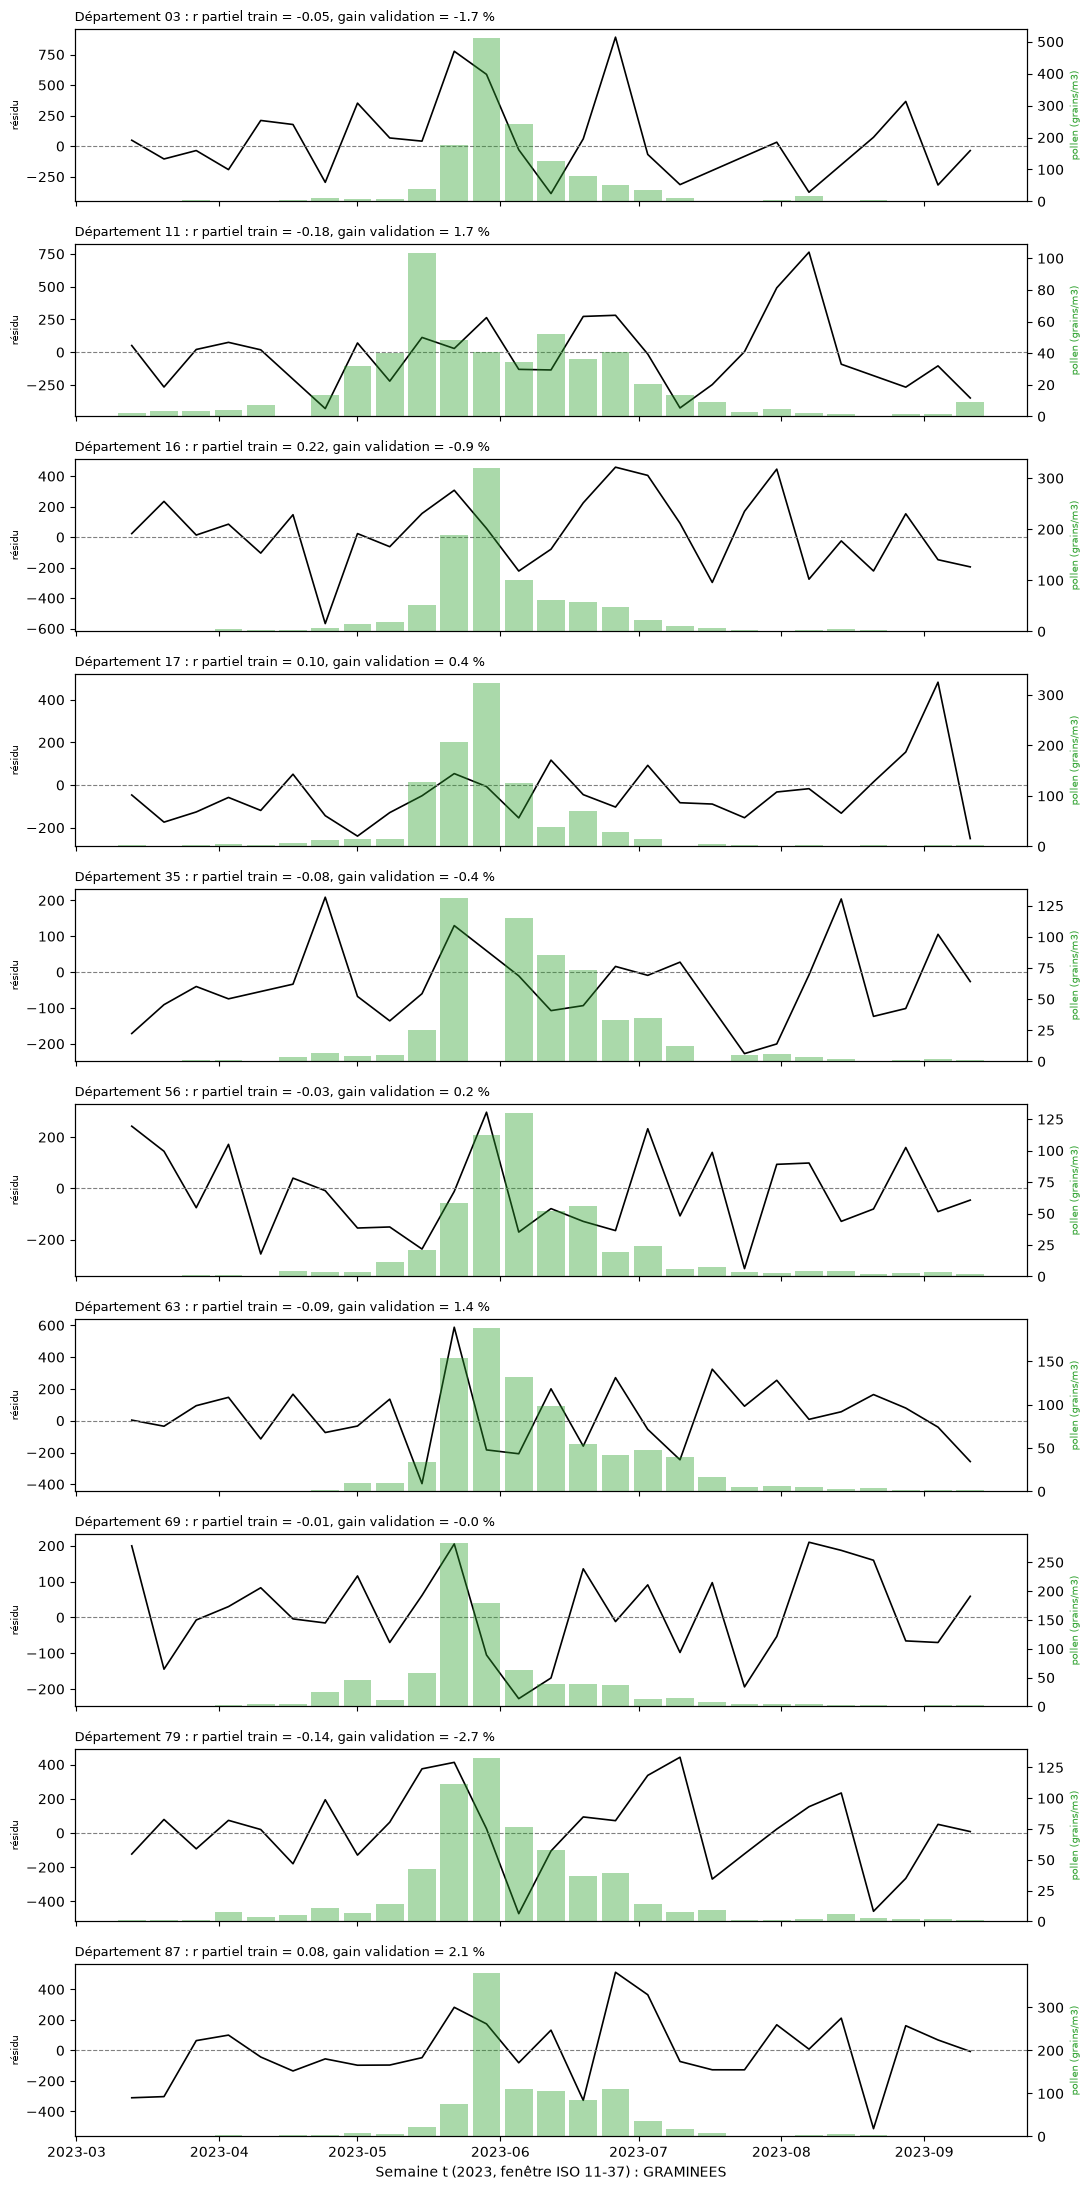

In [40]:
depts = [d for d in PILOTES if d in test_gram.index]
fig, axes = plt.subplots(len(depts), 1, figsize=(11, 2.2 * len(depts)), sharex=True)
for ax, dept in zip(axes, depts):
    v = val_all[val_all["code_dept"] == dept].sort_values("date")
    ax.plot(v["date"], v["res"], color="black", lw=1.2)
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_ylabel("résidu", fontsize=7)
    ax2 = ax.twinx()
    ax2.bar(v["date"], v["pollen"], width=6, color="tab:green", alpha=0.4)
    ax2.set_ylabel("pollen (grains/m3)", fontsize=7, color="tab:green")
    t = test_gram.loc[dept]
    ax.set_title(f"Département {dept} : r partiel train = {t['r_partiel_train']:.2f}, "
                 f"gain validation = {t['gain_pollen_%']:.1f} %", fontsize=9, loc="left")
axes[-1].set_xlabel(f"Semaine t (2023, fenêtre ISO {s_deb}-{s_fin}) : {TAXON}")
plt.tight_layout()
plt.show()